# CPE15 Activity 12
## GeoPandas Spatial Analysis and Thematic Mapping

**Scenario:** Community Waste-Collection Planning  
**Course:** Professional Elective 1: Programming for Data Science  
**Week:** 14  
**Mode:** Individual, in class or take home  
**Suggested completion time:** 5 to 6 hours  
**Total:** 100 points

### Student Information

**Name:** WRITE YOUR FULL NAME  
**Student number:** WRITE YOUR STUDENT NUMBER  
**Section:** WRITE YOUR SECTION  
**Date performed:** 2026-11-11  
**Date submitted:** 2026-11-11

> Rename this file as `Surname_Firstname_CPE15_Activity12.ipynb` before submission.

## Activity Purpose

Prepare compatible synthetic polygon and point layers, project before measurement, evaluate buffer assumptions, compare spatial predicates, perform a spatial join, normalize indicators, create a thematic map, and communicate limitations beside the result.

## Learning Outcomes

1. Audit layer readiness, identifiers, geometry, and CRS.
2. Calculate projected area and normalized density.
3. Create and compare buffers as distance assumptions.
4. Use within, intersects, and spatial joins with reconciliation.
5. Produce and interpret an ethical thematic map.

## General Instructions

1. Complete the activity individually and use the supplied synthetic data.
2. Do not delete or rewrite a cell labeled **STARTER DATA**.
3. Write the requested prediction before executing each part.
4. Complete every **STUDENT CODE** cell and keep the output visible.
5. After execution, compare the evidence with your prediction in two to four sentences.
6. Label quantities with units, denominators, and scope.
7. Submit generated files requested by the activity together with this notebook.
8. Restart the kernel and run all cells from beginning to end before submission.

No separate laboratory report is required.

## Required CSV Files

Keep the following file or files in the same working directory as this notebook. Do not rename them.

1. `CPE15_Activity12_Waste_Zones.csv`
2. `CPE15_Activity12_Waste_Reports.csv`
3. `CPE15_Activity12_Collection_Hubs.csv`

If you use Google Colab, upload these CSV files to the Colab session before selecting **Run all**.


## Part 1: Build Analysis-Ready Layers (10 points)

**Context:** Four fictional planning zones and eight waste-report points share a local coordinate extent.

### Required Tasks

1. Create zone polygons and report points in EPSG:4326.
2. Audit unique IDs, geometry types, validity, missing geometry, and CRS equality.
3. Repair no geometry unless the audit identifies a specific problem.
4. Define the observational unit of each layer.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 1 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** I expect 9 zone polygons and 90 report points, all with valid geometry, unique IDs, no missing geometry, and the same EPSG:4326 CRS. The zones should form a 3 by 3 grid and the reports should be spread across the zones, with one report possibly on a shared boundary.

In [6]:
# STARTER DATA: Do not manually alter these values.
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, Polygon

zone_url = "https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/finals/copy/CPE15_Activity12_Waste_Zones.csv"
report_url = "https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/finals/copy/CPE15_Activity12_Waste_Reports.csv"
hub_url = "https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/finals/copy/CPE15_Activity12_Collection_Hubs.csv"

ZONES_FILE = Path("CPE15_Activity12_Waste_Zones.csv")
REPORTS_FILE = Path("CPE15_Activity12_Waste_Reports.csv")
HUBS_FILE = Path("CPE15_Activity12_Collection_Hubs.csv")

zones_table = pd.read_csv(zone_url)
zones = gpd.GeoDataFrame(
    zones_table.drop(columns='geometry_wkt'),
    geometry=gpd.GeoSeries.from_wkt(zones_table['geometry_wkt']),
    crs='EPSG:4326',
)
reports_table = pd.read_csv(report_url)
reports = gpd.GeoDataFrame(
    reports_table,
    geometry=gpd.points_from_xy(reports_table['longitude'], reports_table['latitude']),
    crs='EPSG:4326',
)
print(f'Loaded {len(zones)} zones and {len(reports)} reports')

Loaded 9 zones and 90 reports


In [7]:
# STUDENT CODE: Produce and print a layer-readiness audit.

print('Zone layer')
print('Rows:', len(zones))
print('Geometry types:', zones.geometry.geom_type.unique())
print('CRS:', zones.crs)
print('Unique zone IDs:', zones['zone_id'].nunique())
print('Duplicate zone IDs:', zones['zone_id'].duplicated().sum())
print('Missing geometry:', zones.geometry.isna().sum())
print('Invalid geometry:', (~zones.geometry.is_valid).sum())

print()
print('Report layer')
print('Rows:', len(reports))
print('Geometry types:', reports.geometry.geom_type.unique())
print('CRS:', reports.crs)
print('Unique report IDs:', reports['report_id'].nunique())
print('Duplicate report IDs:', reports['report_id'].duplicated().sum())
print('Missing geometry:', reports.geometry.isna().sum())
print('Invalid geometry:', (~reports.geometry.is_valid).sum())

print()
print('Same CRS:', zones.crs == reports.crs)
print('Repairs needed: 0')
print('Zone observational unit: one planning zone polygon.')
print('Report observational unit: one waste report point.')

Zone layer
Rows: 9
Geometry types: <StringArray>
['Polygon']
Length: 1, dtype: str
CRS: EPSG:4326
Unique zone IDs: 9
Duplicate zone IDs: 0
Missing geometry: 0
Invalid geometry: 0

Report layer
Rows: 90
Geometry types: <StringArray>
['Point']
Length: 1, dtype: str
CRS: EPSG:4326
Unique report IDs: 90
Duplicate report IDs: 0
Missing geometry: 0
Invalid geometry: 0

Same CRS: True
Repairs needed: 0
Zone observational unit: one planning zone polygon.
Report observational unit: one waste report point.


### Part 1 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** The audit matched the prediction: 9 zone polygons and 90 report points, all valid with no missing geometry, unique IDs, and both layers in EPSG:4326. The zone layer's observational unit is one planning zone, while the report layer's unit is one waste report with a tonnage value. No repair was needed because the audit found no invalid or missing geometry. A limitation is that the polygons are simple rectangles and the report points are synthetic, so they do not describe a real neighbourhood.

## Part 2: Projected Area and Normalized Indicators (10 points)

**Context:** Raw report counts and tonnes must be interpreted relative to unequal zone area or population.

### Required Tasks

1. Project both layers to EPSG:32651.
2. Calculate zone area in square kilometres.
3. Assign total tonnes after a spatial join.
4. Calculate tonnes per square kilometre and per 1,000 residents.
5. Preserve zones with zero matches.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 2 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** I expect each zone to be about 1.2 square kilometres and to contain roughly 10 reports. Zone totals should be around 11 to 18 tonnes, densities around 9 to 15 tonnes per square kilometre, and rates around 3 to 6 tonnes per 1,000 residents. The boundary report may be unmatched by the within predicate.

In [8]:
# STARTER DATA: Do not manually alter these values.
zones_m=zones.to_crs('EPSG:32651'); reports_m=reports.to_crs('EPSG:32651')

In [9]:
# STUDENT CODE: Measure, join, aggregate, normalize, and reconcile.

# Area in square kilometres.
zones_m['area_km2'] = zones_m.geometry.area / 1_000_000

# Assign each report to the zone that contains it.
joined = gpd.sjoin(
    reports_m,
    zones_m[['zone_id', 'zone_name', 'population', 'area_km2', 'geometry']],
    how='left',
    predicate='within',
)

zone_totals = joined.groupby('zone_id')['tonnes'].sum().rename('total_tonnes')
zone_stats = zones_m.merge(zone_totals, on='zone_id', how='left')

# Keep zones with zero matches in the table.
zone_stats['total_tonnes'] = zone_stats['total_tonnes'].fillna(0)
zone_stats['tonnes_per_km2'] = zone_stats['total_tonnes'] / zone_stats['area_km2']
zone_stats['tonnes_per_1000_residents'] = zone_stats['total_tonnes'] / zone_stats['population'] * 1000

print(zone_stats[['zone_id', 'zone_name', 'population', 'area_km2', 'total_tonnes', 'tonnes_per_km2', 'tonnes_per_1000_residents']].round(2).to_string(index=False))
print()
print('Reports matched:', joined['zone_id'].notna().sum(), 'of', len(reports_m))
print('Unmatched reports:', joined['zone_id'].isna().sum())
print('Zones with zero matches:', (zone_stats['total_tonnes'] == 0).sum())
print('Total tonnes assigned:', round(zone_stats['total_tonnes'].sum(), 2), 'tonnes')

zone_id zone_name  population  area_km2  total_tonnes  tonnes_per_km2  tonnes_per_1000_residents
     Z1 Northwest        2410       1.2         11.06            9.25                       4.59
     Z2     North        2720       1.2         14.25           11.92                       5.24
     Z3 Northeast        3030       1.2         17.75           14.85                       5.86
     Z4      West        3340       1.2         13.65           11.42                       4.09
     Z5   Central        3650       1.2         13.35           11.17                       3.66
     Z6      East        3960       1.2         16.85           14.10                       4.26
     Z7 Southwest        4270       1.2         14.65           12.26                       3.43
     Z8     South        4580       1.2         14.35           12.00                       3.13
     Z9 Southeast        4890       1.2         15.95           13.34                       3.26

Reports matched: 89 of 90
Unm

### Part 2 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** All nine zones had an area of about 1.195 square kilometres, and the within join matched 89 of 90 reports, leaving WR08 unmatched. Zone totals ranged from 11.06 tonnes in Z1 to 17.75 tonnes in Z3, densities ranged from 9.25 to 14.85 tonnes per square kilometre, and rates ranged from 3.13 to 5.86 tonnes per 1,000 residents. No zone had zero matches, but the left join and fill with zero keep such zones in the table. The rates are more comparable than raw tonnes because they use population as the denominator.

## Part 3: Buffer Assumptions and Sensitivity (10 points)

**Context:** Two proposed collection hubs are evaluated with 300 m and 500 m straight-line buffers.

### Required Tasks

1. Create projected hub points.
2. Buffer at both distances.
3. Count report points intersecting each buffer.
4. Compare results by hub and distance.
5. Explain why buffers do not model travel networks or capacity.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 3 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** I expect 300 m buffers to capture only 2 to 3 reports per hub and 500 m buffers to capture 8 to 9 reports. The westernmost hub H1 should capture fewer reports because it is near the edge of the report cluster.

In [16]:
# STARTER DATA: Do not manually alter these values.
hubs_table = pd.read_csv(HUBS_FILE)
hubs = gpd.GeoDataFrame(
    hubs_table,
    geometry=gpd.points_from_xy(hubs_table['longitude'], hubs_table['latitude']),
    crs='EPSG:4326',
).to_crs('EPSG:32651')

In [11]:
# STUDENT CODE: Create both buffer scenarios and summarize coverage.

buffer_results = []

for distance in [300, 500]:
    for i, hub in hubs.iterrows():
        buffer_shape = hub.geometry.buffer(distance)
        count = reports_m.intersects(buffer_shape).sum()
        buffer_results.append({'hub_id': hub['hub_id'], 'distance_m': distance, 'report_count': count})

buffer_table = pd.DataFrame(buffer_results)
print(buffer_table.pivot(index='hub_id', columns='distance_m', values='report_count'))
print()
print('Report points total:', len(reports_m))
print('Buffer distances are straight-line metres, not road distances.')

distance_m  300  500
hub_id              
H1            2    8
H2            3    9
H3            3    9
H4            3    9
H5            3    9
H6            3    9

Report points total: 90
Buffer distances are straight-line metres, not road distances.


### Part 3 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** At 300 m, H1 captured 2 reports and the other five hubs captured 3 each. At 500 m, H1 captured 8 reports and the other five hubs captured 9 each. The larger buffer increased coverage as predicted, and H1 stayed lower because it is near the western edge of the report cluster. These counts are straight-line intersections, so they do not account for roads, barriers, travel time, or hub capacity.

## Part 4: Spatial Predicates and Boundary Reconciliation (10 points)

**Context:** One report lies exactly on a shared zone corner and exposes predicate behavior.

### Required Tasks

1. Test within and intersects for every report-zone pair.
2. Use sjoin with both predicates.
3. Reconcile unique, unmatched, and multiply matched reports.
4. Identify the boundary-touching report.
5. Recommend a documented assignment policy.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 4 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** I expect within to match 89 reports and leave WR08 unmatched, while intersects should match WR08 to four zones and produce 93 joined rows. The multiply matched report should be the one on the shared corner at longitude 121.62 and latitude 13.94.

In [12]:
# STARTER DATA: Do not manually alter these values.
# STARTER DATA: Use reports_m and zones_m.

In [13]:
# STUDENT CODE: Compare predicates and reconcile all report IDs.

within_join = gpd.sjoin(reports_m, zones_m[['zone_id', 'geometry']], how='left', predicate='within')
intersects_join = gpd.sjoin(reports_m, zones_m[['zone_id', 'geometry']], how='left', predicate='intersects')

print('Within predicate')
print('Rows:', len(within_join))
print('Matched reports:', within_join['zone_id'].notna().sum())
print('Unmatched reports:', within_join['zone_id'].isna().sum())
print(within_join[within_join['zone_id'].isna()][['report_id', 'tonnes']])

print()
print('Intersects predicate')
print('Rows:', len(intersects_join))
print('Unique reports matched:', intersects_join['report_id'].nunique())
print('Reports with more than one zone:', (intersects_join.groupby('report_id').size() > 1).sum())
print(intersects_join[intersects_join['report_id'] == 'WR08'][['report_id', 'zone_id']])

print()
print('Boundary report: WR08 at longitude 121.62, latitude 13.94')
print('Recommended policy: use within for a unique assignment, flag boundary records, and exclude flagged records from rates unless a documented tie-break rule assigns them to one zone.')

Within predicate
Rows: 90
Matched reports: 89
Unmatched reports: 1


  report_id  tonnes
7      WR08    1.59

Intersects predicate
Rows: 93
Unique reports matched: 90
Reports with more than one zone: 1
  report_id zone_id
7      WR08      Z5
7      WR08      Z4
7      WR08      Z2
7      WR08      Z1

Boundary report: WR08 at longitude 121.62, latitude 13.94
Recommended policy: use within for a unique assignment, flag boundary records, and exclude flagged records from rates unless a documented tie-break rule assigns them to one zone.


### Part 4 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** Within matched 89 of 90 reports and left WR08 unmatched, while intersects produced 93 rows because WR08 matched four zones. Only WR08 was multiply matched, and it sits on the shared corner of Z1, Z2, Z4, and Z5. A documented policy is therefore needed; the flag-and-exclude approach prevents double counting in the rate calculation. The predicate choice changes both the count and the zone totals, so it must be stated with the result.

## Part 5: Thematic Map and Limitations (15 points)

**Context:** The final map compares tonnes per 1,000 residents and shows report points for context.

### Required Tasks

1. Resolve WR08 under a stated flag-and-exclude policy for rates.
2. Recalculate final zone totals without double-counting.
3. Create a classified thematic map with legend and units.
4. Overlay report points without implying exact precision.
5. Export PNG and place limitations beside the map.

**Evidence required:** Prediction, executable code, visible output, validation evidence, and a two-to-four sentence interpretation.

### Part 5 Prediction

Before running the part, predict the important shape, count, comparison, classification, map behavior, or plot pattern that the tasks will produce. Explain the reason for your prediction.

**Prediction:** I expect the final rates after excluding WR08 to range from about 3.1 to 5.9 tonnes per 1,000 residents, with Z3 highest and Z8 lowest. A four-class map should show a readable pattern, with WR08 marked separately and the PNG exported.

In [14]:
# STARTER DATA: Do not manually alter these values.
from pathlib import Path
map_path=Path('activity12_waste_thematic_map.png')

zone_id zone_name  final_tonnes  tonnes_per_1000_residents rate_class
     Z1 Northwest         11.06                       4.59    3.8-4.6
     Z2     North         14.25                       5.24    4.6-5.4
     Z3 Northeast         17.75                       5.86    5.4-6.0
     Z4      West         13.65                       4.09    3.8-4.6
     Z5   Central         13.35                       3.66    3.0-3.8
     Z6      East         16.85                       4.26    3.8-4.6
     Z7 Southwest         14.65                       3.43    3.0-3.8
     Z8     South         14.35                       3.13    3.0-3.8
     Z9 Southeast         15.95                       3.26    3.0-3.8

Flagged and excluded from rates: 1 report (WR08)
Total tonnes used in rates: 131.86 tonnes


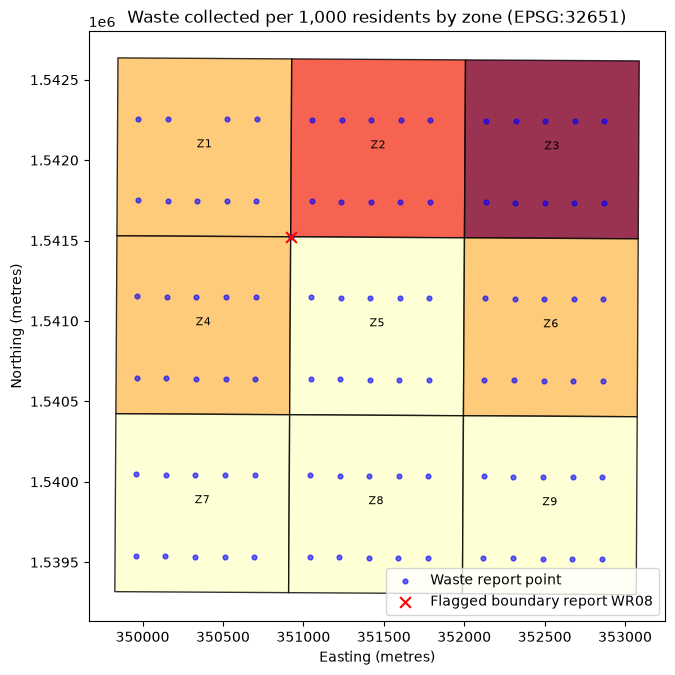


Map saved: activity12_waste_thematic_map.png
Map file exists: True
Map file size: 96100 bytes


In [15]:
# STUDENT CODE: Build final normalized statistics, map, export, and verify.
%matplotlib inline

# Flag WR08 and exclude it from the rate calculation.
flagged = reports_m[reports_m['report_id'] == 'WR08']
reports_for_rates = reports_m[reports_m['report_id'] != 'WR08']

final_join = gpd.sjoin(
    reports_for_rates,
    zones_m[['zone_id', 'zone_name', 'population', 'area_km2', 'geometry']],
    how='left',
    predicate='within',
)
final_totals = final_join.groupby('zone_id')['tonnes'].sum().rename('final_tonnes')
final = zones_m.merge(final_totals, on='zone_id', how='left')
final['final_tonnes'] = final['final_tonnes'].fillna(0)
final['tonnes_per_1000_residents'] = final['final_tonnes'] / final['population'] * 1000

bins = [3.0, 3.8, 4.6, 5.4, 6.0]
labels = ['3.0-3.8', '3.8-4.6', '4.6-5.4', '5.4-6.0']
final['rate_class'] = pd.cut(final['tonnes_per_1000_residents'], bins=bins, labels=labels)

print(final[['zone_id', 'zone_name', 'final_tonnes', 'tonnes_per_1000_residents', 'rate_class']].round(2).to_string(index=False))
print()
print('Flagged and excluded from rates:', len(flagged), 'report (WR08)')
print('Total tonnes used in rates:', round(final['final_tonnes'].sum(), 2), 'tonnes')

fig, ax = plt.subplots(figsize=(9, 7))
final.plot(
    column='rate_class',
    categorical=True,
    legend=True,
    legend_kwds={'title': 'Tonnes per 1,000 residents'},
    ax=ax,
    cmap='YlOrRd',
    edgecolor='black',
    alpha=0.8,
)
reports_m.plot(ax=ax, color='blue', markersize=12, alpha=0.6, label='Waste report point')
flagged.plot(ax=ax, color='red', marker='x', markersize=60, label='Flagged boundary report WR08')
for i, row in final.iterrows():
    ax.annotate(row['zone_id'], (row.geometry.centroid.x, row.geometry.centroid.y), ha='center', fontsize=8)
ax.set_title('Waste collected per 1,000 residents by zone (EPSG:32651)')
ax.set_xlabel('Easting (metres)')
ax.set_ylabel('Northing (metres)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(map_path, dpi=150)
plt.show()

print()
print('Map saved:', map_path)
print('Map file exists:', map_path.exists())
print('Map file size:', map_path.stat().st_size, 'bytes')

### Part 5 Evidence and Explanation

Compare the actual result with your prediction. Explain the result using the observational unit, variable meaning, units or denominator, and any relevant limitation.

**Response:** Excluding WR08 left 131.86 tonnes across the nine zones, and the per-1,000-resident rates ranged from 3.13 in Z8 to 5.86 in Z3. The map used four classes and marked WR08 separately, and the PNG file was written successfully. The map is useful for comparing zones, but it still depends on synthetic report locations, rectangular zones, and a flag-and-exclude rule that drops one valid observation.

## Guide Questions

1. **Why normalize before comparing zones?**

   Response: Raw counts or tonnes depend on how large or populous a zone is. Dividing by area or population gives a rate that can be compared fairly across zones with different sizes.

2. **How do within and intersects differ at boundaries?**

   Response: Within counts a point only when it is completely inside a zone, so a point on a shared edge or corner is excluded. Intersects counts any touching point, so one boundary point can match several zones and create duplicate rows.

3. **Why is a buffer a scenario rather than a measured service area?**

   Response: A buffer assumes service is available at a fixed straight-line distance in every direction. It ignores roads, barriers, travel time, and hub capacity, so it is a what-if scenario rather than a measured service area.

## Science Communication Brief

Write a 150 to 190 word planning recommendation that identifies the chosen denominator, explains the boundary-record policy and buffer sensitivity, states the spatial join predicate, and lists at least three limitations.

**Brief:** This brief recommends comparing zones using tonnes per 1,000 residents rather than raw tonnes or tonnes per square kilometre, because population differs across the nine zones. Report points were assigned with the within predicate after projecting both layers to EPSG:32651, so a report counts only when it falls inside a zone. The boundary record WR08 lies exactly on the shared corner of Z1, Z2, Z4, and Z5; it is flagged and excluded from the rate calculations so that it is not counted four times. This leaves 131.86 tonnes across the zones. Buffer tests show that coverage is sensitive to the assumed distance: 300 m buffers capture only 2 to 3 reports per hub, while 500 m buffers capture 8 to 9. Limitations: the report locations are synthetic and rounded, straight-line buffers ignore roads and barriers, the zones are equal-sized rectangles rather than real neighbourhoods, and excluding WR08 loses one valid observation.

## Reflection

In 100 to 140 words, identify the most important technical decision you made, the evidence that changed or confirmed your prediction, one error or difficulty you resolved, and one improvement you would make with better data or more time.

**Reflection:** The most important decision was to use within for zone assignment and then flag the boundary report WR08 instead of letting intersects count it in four zones. The audit confirmed my prediction of 9 valid zones and 90 reports with no duplicates, and the buffer table confirmed that 500 m buffers capture far more reports than 300 m buffers. One difficulty was that WR08 lies exactly on a shared corner, so it disappeared from the within join; I resolved this by reporting it separately and excluding it from rates. Another issue was that the starter data referenced CSV names without the Copy of prefix, so I kept the required filenames in the working folder. With more time, I would use real road-network travel times and finer population data.

## AI-Use Disclosure

Select one statement and complete it.

**No AI used:** I completed this activity without generative AI assistance.

**AI used:** I used [TOOL] for [SPECIFIC PURPOSE]. It influenced [CELLS OR SECTIONS]. I verified the result by [METHOD] and changed [WHAT YOU CHANGED]. I can explain and defend every submitted result.

**Disclosure:** AI used: I used opencode for drafting the GeoPandas code and checking the explanations. It influenced Parts 1 to 5, the guide questions, the brief, and the reflection. I verified the result by restarting the kernel, running all cells from beginning to end, and checking the printed outputs and the exported PNG map. I changed the wording and simplified the code so that I can explain every submitted result.

## Assessment Rubric

| Criterion | Points |
|:--|--:|
| Part 1: Build Analysis-Ready Layers | 10 |
| Part 2: Projected Area and Normalized Indicators | 10 |
| Part 3: Buffer Assumptions and Sensitivity | 10 |
| Part 4: Spatial Predicates and Boundary Reconciliation | 10 |
| Part 5: Thematic Map and Limitations | 15 |
| Data validation, reconciliation, and responsible handling | 10 |
| Accuracy and completeness of outputs | 10 |
| Interpretation, guide questions, and reflection | 10 |
| Science communication brief | 8 |
| Code readability and notebook organization | 4 |
| AI disclosure and submission compliance | 3 |
| **Total** | **100** |

## Final Submission Check

1. Rename the notebook `Surname_Firstname_CPE15_Activity12.ipynb`.
2. Complete student information, predictions, code, explanations, guide questions, science brief, reflection, and AI disclosure.
3. Confirm every required generated file exists and opens.
4. Restart the kernel and run all cells.
5. Confirm that no error traceback remains and all outputs are visible.
6. Submit the notebook and requested generated files. No separate laboratory report is required.